In [2]:
from pathlib import Path
import sys
import pandas as pd
import torch

DATA_DIR = Path("data")
TRAIN_DIR = DATA_DIR / "train"

assert TRAIN_DIR.is_dir(), "Open the notebook from the main project folder."

df = pd.read_csv(DATA_DIR / "driver_imgs_list.csv")

print("Python interpreter:", sys.executable)
print("MPS available:", torch.backends.mps.is_available())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Python interpreter: /Users/ramonfloresarteaga/Desktop/Essex University/Codes/distracted_driver_classification/.venv/bin/python
MPS available: True
Dataset shape: (22424, 3)
Columns: ['subject', 'classname', 'img']


,subject,classname,img
0,p002,c0,img_44733.jpg
1,p002,c0,img_72999.jpg
2,p002,c0,img_25094.jpg
3,p002,c0,img_69092.jpg
4,p002,c0,img_92629.jpg


In [3]:
# Construct each image path from its class folder and filename.
df["image_path"] = [
    TRAIN_DIR / class_name / filename
    for class_name, filename in zip(df["classname"], df["img"])
]

missing_images = sum(not path.is_file() for path in df["image_path"])

print("Total images:", len(df))
print("Unique drivers:", df["subject"].nunique())
print("Missing images:", missing_images)
print("Duplicate filenames:", df["img"].duplicated().sum())

class_counts = df["classname"].value_counts().sort_index()
display(class_counts.rename("Image count").to_frame())

Total images: 22424
Unique drivers: 26
Missing images: 0
Duplicate filenames: 0


,Image count
classname,
c0,2489
c1,2267
c2,2317
c3,2346
c4,2326
c5,2312
c6,2325
c7,2002
c8,1911


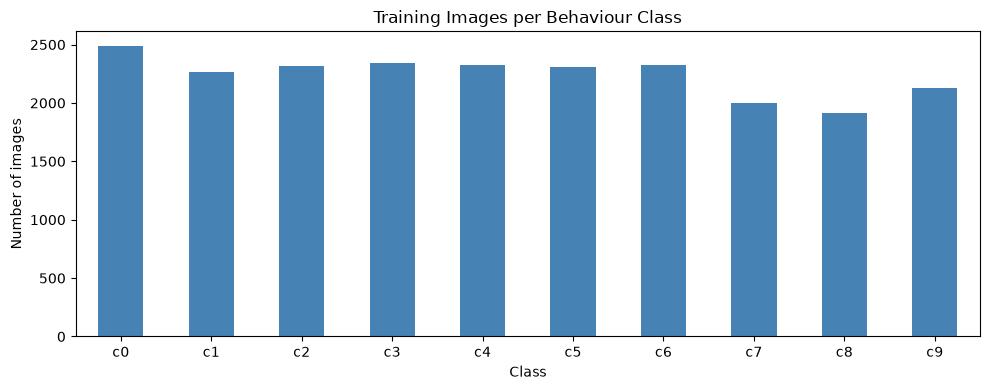

In [4]:
import matplotlib.pyplot as plt

ax = class_counts.plot.bar(figsize=(10, 4), color="steelblue")
ax.set_title("Training Images per Behaviour Class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

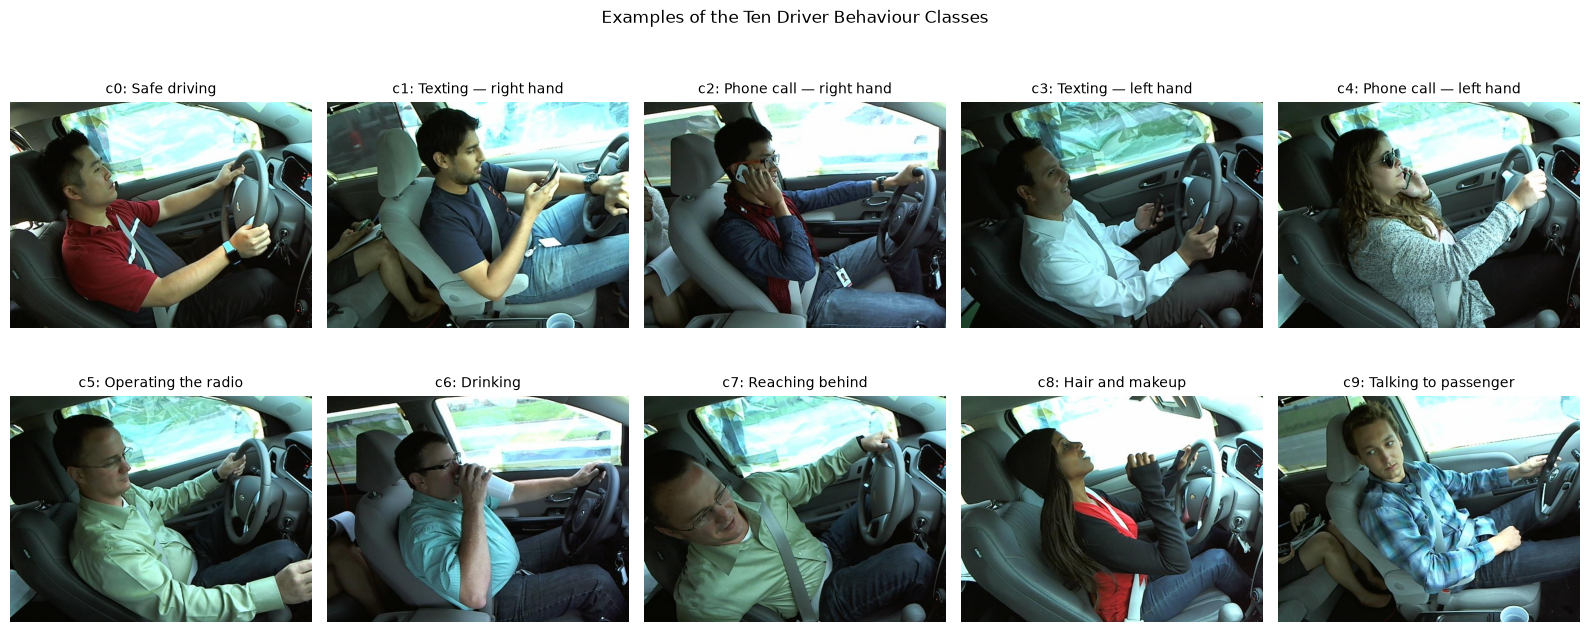

In [5]:
from PIL import Image

CLASS_NAMES = {
    "c0": "Safe driving",
    "c1": "Texting — right hand",
    "c2": "Phone call — right hand",
    "c3": "Texting — left hand",
    "c4": "Phone call — left hand",
    "c5": "Operating the radio",
    "c6": "Drinking",
    "c7": "Reaching behind",
    "c8": "Hair and makeup",
    "c9": "Talking to passenger",
}

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, (class_id, description) in zip(axes.flat, CLASS_NAMES.items()):
    row = df[df["classname"] == class_id].sample(
        n=1, random_state=42
    ).iloc[0]

    with Image.open(row["image_path"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f"{class_id}: {description}", fontsize=10)
    ax.axis("off")

plt.suptitle("Examples of the Ten Driver Behaviour Classes")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold

# Fix the seed so the data splits can be reproduced.
SEED = 42

# Reserve approximately 20% of drivers for final testing.
# Grouping by subject keeps each driver's images in only one split.
test_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED,
)

dev_indices, test_indices = next(
    test_splitter.split(
        X=df,
        y=df["classname"],
        groups=df["subject"],
    )
)

# Use development data for model selection and cross-validation.
# Keep test data untouched until both models and settings are finalised.
dev_df = df.iloc[dev_indices].reset_index(drop=True)
test_df = df.iloc[test_indices].reset_index(drop=True)

# Confirm that development and test sets share no drivers.
dev_drivers = set(dev_df["subject"])
test_drivers = set(test_df["subject"])

assert dev_drivers.isdisjoint(test_drivers), "Driver leakage detected!"

# Check that all ten classes are represented in both sets.
expected_classes = set(CLASS_NAMES)
assert set(dev_df["classname"]) == expected_classes
assert set(test_df["classname"]) == expected_classes

# Create five folds within the development set.
# Stratification aims to balance classes while keeping drivers together.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

# Save these indices so SVM and CNN use exactly the same folds.
cv_splits = list(
    cv.split(
        X=dev_df,
        y=dev_df["classname"],
        groups=dev_df["subject"],
    )
)

print(
    f"Development: {len(dev_df):,} images, "
    f"{len(dev_drivers)} drivers"
)
print(
    f"Final test:  {len(test_df):,} images, "
    f"{len(test_drivers)} drivers"
)

# Check every fold for driver overlap and missing classes.
fold_summary = []

for fold_number, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    fold_train = dev_df.iloc[train_idx]
    fold_val = dev_df.iloc[val_idx]

    train_drivers = set(fold_train["subject"])
    val_drivers = set(fold_val["subject"])

    assert train_drivers.isdisjoint(val_drivers), "Fold driver leakage!"
    assert set(fold_train["classname"]) == expected_classes
    assert set(fold_val["classname"]) == expected_classes

    fold_summary.append({
        "Fold": fold_number,
        "Training images": len(fold_train),
        "Validation images": len(fold_val),
        "Training drivers": len(train_drivers),
        "Validation drivers": len(val_drivers),
    })

display(pd.DataFrame(fold_summary))

Development: 17,446 images, 20 drivers
Final test:  4,978 images, 6 drivers


,Fold,Training images,Validation images,Training drivers,Validation drivers
0,1,13874,3572,16,4
1,2,13808,3638,16,4
2,3,14220,3226,16,4
3,4,13883,3563,16,4
4,5,13999,3447,16,4


Original size: (640, 480)
Resized size: (128, 96)
HOG features per image: 1260
Class: Safe driving


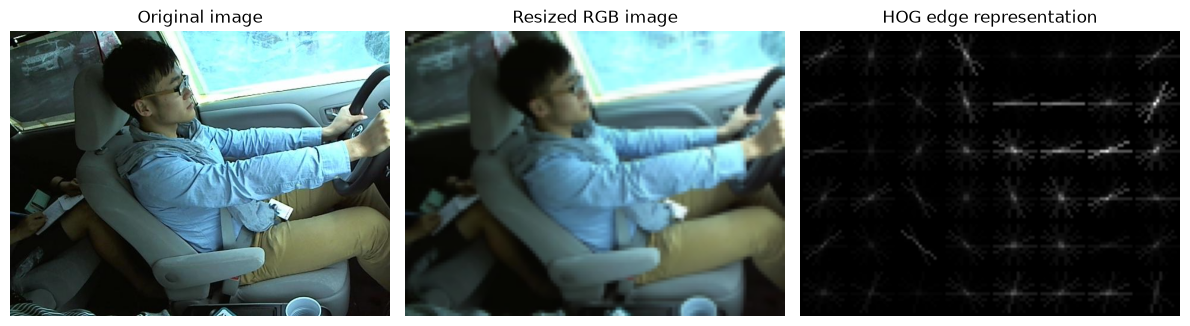

In [7]:
import numpy as np
from skimage.feature import hog

# PIL expects image dimensions in (width, height) order.
# This size preserves the 4:3 ratio of a 640 × 480 source image.
IMAGE_SIZE = (128, 96)

# Define the SVM's handcrafted feature extraction settings.
# HOG describes local edge directions and object shapes.
HOG_PARAMS = {
    "orientations": 9,
    "pixels_per_cell": (16, 16),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
    "feature_vector": True,
}

# Select a development image; leave the final test set untouched.
sample_row = dev_df.iloc[0]

with Image.open(sample_row["image_path"]) as image:
    original_rgb = image.convert("RGB")

    # Resize consistently for both modelling pipelines.
    resized_rgb = original_rgb.resize(
        IMAGE_SIZE,
        resample=Image.Resampling.BILINEAR,
    )

    # Convert to grayscale for HOG feature extraction.
    grayscale = resized_rgb.convert("L")
    gray_array = np.asarray(grayscale, dtype=np.float32) / 255.0

    print("Original size:", original_rgb.size)
    print("Resized size:", resized_rgb.size)

# Generate the feature vector and a visualisation of its edge patterns.
hog_features, hog_image = hog(
    gray_array,
    visualize=True,
    **HOG_PARAMS,
)

print("HOG features per image:", hog_features.size)
print("Class:", CLASS_NAMES[sample_row["classname"]])

# Compare the original, resized, and HOG representations.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original_rgb)
axes[0].set_title("Original image")

axes[1].imshow(resized_rgb)
axes[1].set_title("Resized RGB image")

axes[2].imshow(hog_image, cmap="gray")
axes[2].set_title("HOG edge representation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from tqdm.auto import tqdm

# Extract the same HOG representation for every development image.
# No learned preprocessing is fitted here; scaling will be fitted
# separately inside each training fold to prevent data leakage.
def extract_hog_features(image_path):
    with Image.open(image_path) as image:
        grayscale = (
            image.convert("RGB")
            .resize(IMAGE_SIZE, resample=Image.Resampling.BILINEAR)
            .convert("L")
        )

        # Convert pixel values from 0–255 to floating-point values in 0–1.
        gray_array = np.asarray(grayscale, dtype=np.float32) / 255.0

    return hog(
        gray_array,
        visualize=False,
        **HOG_PARAMS,
    ).astype(np.float32)


# Preallocate the feature matrix to keep memory use manageable.
# Row order matches dev_df and the cross-validation indices.
X_hog_dev = np.empty(
    (len(dev_df), hog_features.size),
    dtype=np.float32,
)

for index, image_path in enumerate(
    tqdm(dev_df["image_path"], desc="Extracting development HOG features")
):
    X_hog_dev[index] = extract_hog_features(image_path)

# Convert c0–c9 labels to integers 0–9 for model training.
y_dev = dev_df["classname"].str[1:].astype(int).to_numpy()

# Check the extracted features before training.
assert np.isfinite(X_hog_dev).all(), "Non-finite HOG values found!"

print("Feature matrix shape:", X_hog_dev.shape)
print("Label array shape:", y_dev.shape)
print(f"Feature matrix memory: {X_hog_dev.nbytes / 1024**2:.1f} MiB")

Extracting development HOG features:   0%|          | 0/17446 [00:00<?, ?it/s]

Feature matrix shape: (17446, 1260)
Label array shape: (17446,)
Feature matrix memory: 83.9 MiB


In [10]:
from time import perf_counter
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Use the first saved fold, keeping training and validation drivers separate.
train_idx, val_idx = cv_splits[0]

# Fit scaling only on training data.
# Hinge loss trains a linear SVM using stochastic gradient descent.
fast_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SGDClassifier(
        loss="hinge",
        alpha=0.001,
        max_iter=100,
        tol=0.001,
        early_stopping=False,
        random_state=SEED,
    )),
])

# Time one fold before deciding whether to run all five.
start_time = perf_counter()

fast_svm.fit(X_hog_dev[train_idx], y_dev[train_idx])
val_predictions = fast_svm.predict(X_hog_dev[val_idx])

elapsed_seconds = perf_counter() - start_time

# Report validation performance and optimisation iterations.
print(f"Runtime: {elapsed_seconds:.1f} seconds")
print(f"Accuracy: {accuracy_score(y_dev[val_idx], val_predictions):.4f}")
print(
    f"Macro F1: "
    f"{f1_score(y_dev[val_idx], val_predictions, average='macro', zero_division=0):.4f}"
)
print("Iterations:", fast_svm.named_steps["svm"].n_iter_)

Runtime: 11.0 seconds
Accuracy: 0.6125
Macro F1: 0.6298
Iterations: 100


/Users/ramonfloresarteaga/Desktop/Essex University/Codes/distracted_driver_classification/.venv/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [11]:
# Allow more optimisation iterations to address the convergence warning.
fast_svm.set_params(svm__max_iter=300)

# Repeat the same fold so runtime and performance remain comparable.
start_time = perf_counter()
fast_svm.fit(X_hog_dev[train_idx], y_dev[train_idx])
val_predictions = fast_svm.predict(X_hog_dev[val_idx])

# Report performance and whether the solver reached its iteration limit.
print(f"Runtime: {perf_counter() - start_time:.1f} seconds")
print(f"Accuracy: {accuracy_score(y_dev[val_idx], val_predictions):.4f}")
print(
    f"Macro F1: "
    f"{f1_score(y_dev[val_idx], val_predictions, average='macro', zero_division=0):.4f}"
)
print("Iterations:", fast_svm.named_steps["svm"].n_iter_)

Runtime: 27.3 seconds
Accuracy: 0.6097
Macro F1: 0.6282
Iterations: 300


/Users/ramonfloresarteaga/Desktop/Essex University/Codes/distracted_driver_classification/.venv/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [12]:
# Reduce the learning rate when the training loss stops improving.
# Average model weights across updates to reduce SGD fluctuations.
fast_svm.set_params(
    svm__learning_rate="adaptive",
    svm__eta0=0.01,
    svm__average=True,
    svm__max_iter=300,
)

# Check the revised training strategy on the same driver-separated fold.
start_time = perf_counter()
fast_svm.fit(X_hog_dev[train_idx], y_dev[train_idx])
val_predictions = fast_svm.predict(X_hog_dev[val_idx])

# Report runtime, validation performance, and iterations used.
print(f"Runtime: {perf_counter() - start_time:.1f} seconds")
print(f"Accuracy: {accuracy_score(y_dev[val_idx], val_predictions):.4f}")
print(
    f"Macro F1: "
    f"{f1_score(y_dev[val_idx], val_predictions, average='macro', zero_division=0):.4f}"
)
print("Iterations:", fast_svm.named_steps["svm"].n_iter_)

Runtime: 9.1 seconds
Accuracy: 0.5658
Macro F1: 0.5432
Iterations: 61


In [13]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score

# Evaluate the fixed configuration on all five driver-separated folds.
# Create a fresh model per fold to avoid carrying over fitted weights.
svm_fold_results = []

# Store predictions made only when each image is in a validation fold.
svm_oof_predictions = np.full(len(y_dev), -1, dtype=int)

for fold_number, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    fold_model = clone(fast_svm)
    start_time = perf_counter()

    fold_model.fit(X_hog_dev[train_idx], y_dev[train_idx])
    predictions = fold_model.predict(X_hog_dev[val_idx])
    svm_oof_predictions[val_idx] = predictions

    # Calculate the four metrics required by the assignment.
    svm_fold_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy_score(y_dev[val_idx], predictions),
        "Precision": precision_score(
            y_dev[val_idx], predictions,
            average="macro", zero_division=0,
        ),
        "Recall": recall_score(
            y_dev[val_idx], predictions,
            average="macro", zero_division=0,
        ),
        "Macro F1": f1_score(
            y_dev[val_idx], predictions,
            average="macro", zero_division=0,
        ),
        "Seconds": perf_counter() - start_time,
        "Iterations": fold_model.named_steps["svm"].n_iter_,
    })

    # Print progress immediately after each fold finishes.
    result = svm_fold_results[-1]
    print(
        f"Fold {fold_number}/5 completed: "
        f"macro F1 = {result['Macro F1']:.4f}, "
        f"time = {result['Seconds']:.1f}s",
        flush=True,
    )

# Confirm that every development image received a validation prediction.
assert (svm_oof_predictions >= 0).all()

# Summarise performance and variability across folds.
svm_cv_results = pd.DataFrame(svm_fold_results)
display(svm_cv_results.round(4))

metric_columns = ["Accuracy", "Precision", "Recall", "Macro F1"]
display(
    svm_cv_results[metric_columns]
    .agg(["mean", "std"])
    .round(4)
)

Fold 1/5 completed: macro F1 = 0.5432, time = 9.1s
Fold 2/5 completed: macro F1 = 0.4358, time = 8.4s
Fold 3/5 completed: macro F1 = 0.4428, time = 9.2s
Fold 4/5 completed: macro F1 = 0.4993, time = 9.1s
Fold 5/5 completed: macro F1 = 0.5220, time = 9.2s


,Fold,Accuracy,Precision,Recall,Macro F1,Seconds,Iterations
0,1,0.5658,0.5748,0.5709,0.5432,9.1101,61
1,2,0.4340,0.5725,0.4399,0.4358,8.3683,56
2,3,0.4399,0.5330,0.4529,0.4428,9.1912,63
3,4,0.4917,0.5809,0.4899,0.4993,9.1288,62
4,5,0.5303,0.5623,0.5310,0.5220,9.2012,66


,Accuracy,Precision,Recall,Macro F1
mean,0.4923,0.5647,0.4969,0.4886
std,0.0570,0.0189,0.0545,0.0477


In [14]:
import torch.nn as nn

# Select Apple GPU acceleration when available.
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

class DriverCNN(nn.Module):
    """A compact CNN for the ten driver behaviour classes."""

    def __init__(self):
        super().__init__()

        # Learn increasingly complex spatial patterns from RGB images.
        # Pooling reduces image dimensions and computation.
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Retain a coarse spatial layout with a fixed output size.
            nn.AdaptiveAvgPool2d((3, 4)),
        )

        # Dropout provides regularisation during training.
        # Output ten raw scores; CrossEntropyLoss handles softmax.
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 3 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        # Extract spatial features and produce class scores.
        return self.classifier(self.features(images))


# Initialise the model reproducibly and move it to the selected device.
torch.manual_seed(SEED)
cnn = DriverCNN().to(device)

# Check dimensions using two artificial images, without training.
# PyTorch uses (batch, channels, height, width) dimension order.
cnn.eval()
with torch.no_grad():
    dummy_images = torch.zeros(2, 3, 96, 128, device=device)
    dummy_output = cnn(dummy_images)

print("Device:", device)
print("Output shape:", tuple(dummy_output.shape))
print(
    "Trainable parameters:",
    sum(p.numel() for p in cnn.parameters() if p.requires_grad),
)

Device: mps
Output shape: (2, 10)
Trainable parameters: 123306


In [15]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Resize to the same dimensions used by the HOG pipeline.
# ToTensor scales pixels to [0, 1]; normalisation maps them to [-1, 1].
image_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE[1], IMAGE_SIZE[0]),
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5),
    ),
])

class DriverImageDataset(Dataset):
    """Load labelled RGB images for a selected data split."""

    def __init__(self, dataframe):
        # Reset indices so DataLoader can access rows by position.
        self.rows = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]

        # Read and transform each image when requested.
        with Image.open(row["image_path"]) as image:
            image_tensor = image_transform(image.convert("RGB"))

        label = int(row["classname"][1:])
        return image_tensor, label


# Reuse fold 1 from the SVM evaluation for a comparable timing trial.
cnn_train_idx, cnn_val_idx = cv_splits[0]

# Use zero loader workers for reliable execution in a Mac notebook.
# Shuffle training images; preserve validation order.
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    DriverImageDataset(dev_df.iloc[cnn_train_idx]),
    batch_size=64,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)

val_loader = DataLoader(
    DriverImageDataset(dev_df.iloc[cnn_val_idx]),
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

# Start from a fresh model for this fold.
torch.manual_seed(SEED)
cnn = DriverCNN().to(device)

# Cross-entropy is appropriate for ten mutually exclusive classes.
# Adam updates the CNN weights; weight decay adds regularisation.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    cnn.parameters(),
    lr=0.001,
    weight_decay=0.0001,
)

# Train for one epoch, showing batch-level progress.
start_time = perf_counter()
cnn.train()
training_loss_sum = 0.0

for images, labels in tqdm(train_loader, desc="Training epoch 1"):
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad(set_to_none=True)
    outputs = cnn(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    # Weight batch losses by batch size, including the smaller final batch.
    training_loss_sum += loss.item() * labels.size(0)

# Evaluate on unseen validation drivers without updating model weights.
cnn.eval()
validation_labels = []
validation_predictions = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Validation"):
        outputs = cnn(images.to(device))
        predictions = outputs.argmax(dim=1).cpu().numpy()

        validation_labels.extend(labels.numpy())
        validation_predictions.extend(predictions)

# Report timing and initial validation performance.
print(f"Epoch + validation time: {perf_counter() - start_time:.1f}s")
print(
    f"Training loss: "
    f"{training_loss_sum / len(train_loader.dataset):.4f}"
)
print(
    f"Validation accuracy: "
    f"{accuracy_score(validation_labels, validation_predictions):.4f}"
)
print(
    f"Validation macro F1: "
    f"{f1_score(validation_labels, validation_predictions, average='macro', zero_division=0):.4f}"
)

Training epoch 1:   0%|          | 0/217 [00:00<?, ?it/s]

Validation:   0%|          | 0/56 [00:00<?, ?it/s]

Epoch + validation time: 34.0s
Training loss: 1.8411
Validation accuracy: 0.3992
Validation macro F1: 0.3442


In [16]:
# Record the first epoch that we already completed.
cnn_history = [{
    "Epoch": 1,
    "Training loss": training_loss_sum / len(train_loader.dataset),
    "Validation accuracy": accuracy_score(
        validation_labels, validation_predictions
    ),
    "Validation macro F1": f1_score(
        validation_labels, validation_predictions,
        average="macro", zero_division=0,
    ),
}]

# Continue training the existing model and optimiser for four more epochs.
# Do not recreate cnn here, because that would reset its learned weights.
for epoch in range(2, 6):
    epoch_start = perf_counter()
    cnn.train()
    training_loss_sum = 0.0

    for images, labels in tqdm(
        train_loader, desc=f"Training epoch {epoch}", leave=False
    ):
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients, calculate loss, and update model weights.
        optimizer.zero_grad(set_to_none=True)
        outputs = cnn(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        training_loss_sum += loss.item() * labels.size(0)

    # Evaluate without gradients, with dropout disabled.
    cnn.eval()
    validation_labels = []
    validation_predictions = []

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = cnn(images.to(device))
            predictions = outputs.argmax(dim=1).cpu().numpy()

            validation_labels.extend(labels.numpy())
            validation_predictions.extend(predictions)

    # Store learning progress for a later training-curve visualisation.
    epoch_result = {
        "Epoch": epoch,
        "Training loss": training_loss_sum / len(train_loader.dataset),
        "Validation accuracy": accuracy_score(
            validation_labels, validation_predictions
        ),
        "Validation macro F1": f1_score(
            validation_labels, validation_predictions,
            average="macro", zero_division=0,
        ),
    }
    cnn_history.append(epoch_result)

    # Show results immediately after each epoch.
    print(
        f"Epoch {epoch}/5 | "
        f"Loss: {epoch_result['Training loss']:.4f} | "
        f"Accuracy: {epoch_result['Validation accuracy']:.4f} | "
        f"Macro F1: {epoch_result['Validation macro F1']:.4f} | "
        f"Time: {perf_counter() - epoch_start:.1f}s",
        flush=True,
    )

# Display all five epochs together.
display(pd.DataFrame(cnn_history).round(4))

Training epoch 2:   0%|          | 0/217 [00:00<?, ?it/s]

Epoch 2/5 | Loss: 1.1334 | Accuracy: 0.4922 | Macro F1: 0.4516 | Time: 32.6s


Training epoch 3:   0%|          | 0/217 [00:00<?, ?it/s]

Epoch 3/5 | Loss: 0.8003 | Accuracy: 0.5246 | Macro F1: 0.5047 | Time: 31.9s


Training epoch 4:   0%|          | 0/217 [00:00<?, ?it/s]

Epoch 4/5 | Loss: 0.6181 | Accuracy: 0.5812 | Macro F1: 0.5601 | Time: 31.7s


Training epoch 5:   0%|          | 0/217 [00:00<?, ?it/s]

Epoch 5/5 | Loss: 0.5000 | Accuracy: 0.5697 | Macro F1: 0.5510 | Time: 31.6s


,Epoch,Training loss,Validation accuracy,Validation macro F1
0,1,1.8411,0.3992,0.3442
1,2,1.1334,0.4922,0.4516
2,3,0.8003,0.5246,0.5047
3,4,0.6181,0.5812,0.5601
4,5,0.5000,0.5697,0.5510


In [17]:
# Use the same five-epoch budget for every CNN fold.
CNN_EPOCHS = 5

# Preserve fold 1's model and validation predictions.
# Store models on CPU between folds to release GPU memory.
cnn_fold_models = [cnn.to("cpu")]
cnn_oof_predictions = np.full(len(y_dev), -1, dtype=int)
cnn_oof_predictions[cnn_val_idx] = np.asarray(validation_predictions)

# Calculate the required metrics consistently for both models.
def calculate_metrics(labels, predictions):
    return {
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            labels, predictions, average="macro", zero_division=0
        ),
    }


# Record fold 1 at epoch 5, rather than selecting its best epoch.
cnn_fold_results = [{
    "Fold": 1,
    **calculate_metrics(validation_labels, validation_predictions),
}]

# Train fresh CNNs for folds 2–5; never reuse another fold's weights.
for fold_number, (fold_train_idx, fold_val_idx) in enumerate(
    cv_splits[1:], start=2
):
    torch.manual_seed(SEED)
    fold_model = DriverCNN().to(device)

    fold_optimizer = torch.optim.Adam(
        fold_model.parameters(),
        lr=0.001,
        weight_decay=0.0001,
    )

    # Use identical data splits to those used by the classical model.
    fold_train_loader = DataLoader(
        DriverImageDataset(dev_df.iloc[fold_train_idx]),
        batch_size=64,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(SEED),
    )
    fold_val_loader = DataLoader(
        DriverImageDataset(dev_df.iloc[fold_val_idx]),
        batch_size=64,
        shuffle=False,
        num_workers=0,
    )

    # Train for the fixed budget, reporting progress after each epoch.
    for epoch in range(1, CNN_EPOCHS + 1):
        epoch_start = perf_counter()
        fold_model.train()
        loss_sum = 0.0

        for images, labels in fold_train_loader:
            images = images.to(device)
            labels = labels.to(device)

            fold_optimizer.zero_grad(set_to_none=True)
            outputs = fold_model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            fold_optimizer.step()

            loss_sum += loss.item() * labels.size(0)

        print(
            f"Fold {fold_number}/5 | Epoch {epoch}/{CNN_EPOCHS} | "
            f"Loss: {loss_sum / len(fold_train_loader.dataset):.4f} | "
            f"Time: {perf_counter() - epoch_start:.1f}s",
            flush=True,
        )

    # Evaluate once after the final epoch on this fold's unseen drivers.
    fold_model.eval()
    fold_labels = []
    fold_predictions = []

    with torch.no_grad():
        for images, labels in fold_val_loader:
            outputs = fold_model(images.to(device))
            fold_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
            fold_labels.extend(labels.numpy())

    # Store predictions in their original development-data positions.
    cnn_oof_predictions[fold_val_idx] = np.asarray(fold_predictions)
    fold_metrics = calculate_metrics(fold_labels, fold_predictions)

    cnn_fold_results.append({"Fold": fold_number, **fold_metrics})
    cnn_fold_models.append(fold_model.to("cpu"))

    print(
        f"Fold {fold_number} completed | "
        f"Accuracy: {fold_metrics['Accuracy']:.4f} | "
        f"Macro F1: {fold_metrics['Macro F1']:.4f}",
        flush=True,
    )

# Verify complete validation coverage and summarise fold variability.
assert (cnn_oof_predictions >= 0).all()

cnn_cv_results = pd.DataFrame(cnn_fold_results)
display(cnn_cv_results.round(4))
display(
    cnn_cv_results[metric_columns].agg(["mean", "std"]).round(4)
)

Fold 2/5 | Epoch 1/5 | Loss: 1.9312 | Time: 27.8s
Fold 2/5 | Epoch 2/5 | Loss: 1.2176 | Time: 27.5s
Fold 2/5 | Epoch 3/5 | Loss: 0.8302 | Time: 26.9s
Fold 2/5 | Epoch 4/5 | Loss: 0.6106 | Time: 26.9s
Fold 2/5 | Epoch 5/5 | Loss: 0.4932 | Time: 26.1s
Fold 2 completed | Accuracy: 0.5129 | Macro F1: 0.4845
Fold 3/5 | Epoch 1/5 | Loss: 1.7837 | Time: 27.2s
Fold 3/5 | Epoch 2/5 | Loss: 0.9609 | Time: 26.3s
Fold 3/5 | Epoch 3/5 | Loss: 0.6058 | Time: 26.2s
Fold 3/5 | Epoch 4/5 | Loss: 0.4143 | Time: 26.6s
Fold 3/5 | Epoch 5/5 | Loss: 0.3063 | Time: 27.4s
Fold 3 completed | Accuracy: 0.4603 | Macro F1: 0.4540
Fold 4/5 | Epoch 1/5 | Loss: 1.8487 | Time: 27.0s
Fold 4/5 | Epoch 2/5 | Loss: 1.1710 | Time: 27.1s
Fold 4/5 | Epoch 3/5 | Loss: 0.7889 | Time: 27.9s
Fold 4/5 | Epoch 4/5 | Loss: 0.5646 | Time: 26.9s
Fold 4/5 | Epoch 5/5 | Loss: 0.4459 | Time: 27.5s
Fold 4 completed | Accuracy: 0.4446 | Macro F1: 0.4394
Fold 5/5 | Epoch 1/5 | Loss: 1.7580 | Time: 26.2s
Fold 5/5 | Epoch 2/5 | Loss: 1.0601

,Fold,Accuracy,Precision,Recall,Macro F1
0,1,0.5697,0.6380,0.5634,0.5510
1,2,0.5129,0.5021,0.5069,0.4845
2,3,0.4603,0.5020,0.4530,0.4540
3,4,0.4446,0.5520,0.4398,0.4394
4,5,0.3130,0.3518,0.3137,0.2866


,Accuracy,Precision,Recall,Macro F1
mean,0.4601,0.5092,0.4554,0.4431
std,0.0958,0.1040,0.0931,0.0974


In [18]:
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from time import perf_counter
from torch.utils.data import Dataset, DataLoader
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

weights = MobileNet_V3_Small_Weights.DEFAULT
preprocess = weights.transforms()

# Find an existing image-path column to load original images directly.
path_column = next(
    (
        col for col in dev_df.columns
        if isinstance(dev_df.iloc[0][col], (str, os.PathLike))
        and str(dev_df.iloc[0][col]).lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        )
        and os.path.isfile(dev_df.iloc[0][col])
    ),
    None,
)

class MobileNetDataset(Dataset):
    def __init__(self):
        self.original = (
            DriverImageDataset(dev_df) if path_column is None else None
        )

    def __len__(self):
        return len(dev_df)

    def __getitem__(self, idx):
        if path_column is not None:
            with Image.open(dev_df.iloc[idx][path_column]) as image:
                return preprocess(image.convert("RGB"))

        # Fallback to your existing dataset if paths are not directly available.
        image, _ = self.original[idx]
        if not torch.is_tensor(image):
            return preprocess(image.convert("RGB"))

        if image.ndim == 2:
            image = image.unsqueeze(0)
        if image.shape[0] == 1:
            image = image.repeat(3, 1, 1)

        if image.dtype.is_floating_point:
            if image.min().item() < 0 or image.max().item() > 1:
                raise ValueError(
                    "Existing images are already normalized. "
                    "Paste DriverImageDataset so preprocessing can be corrected."
                )

        return preprocess(image)

mobile_loader = DataLoader(
    MobileNetDataset(),
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

mobile_model = mobilenet_v3_small(weights=weights)
mobile_model.classifier = torch.nn.Identity()
mobile_model = mobile_model.to(device).eval()

def synchronize_device():
    if str(device).startswith("cuda"):
        torch.cuda.synchronize()
    elif str(device).startswith("mps"):
        torch.mps.synchronize()

feature_batches = []
extraction_start = perf_counter()

with torch.inference_mode():
    for batch_number, images in enumerate(mobile_loader, start=1):
        features = mobile_model(images.to(device))
        feature_batches.append(features.cpu().numpy())

        if batch_number == 2 or batch_number % 20 == 0:
            synchronize_device()
            processed = sum(len(x) for x in feature_batches)
            elapsed = perf_counter() - extraction_start
            estimated_remaining = (
                elapsed / processed * (len(dev_df) - processed)
            )
            print(
                f"Features: {processed}/{len(dev_df)} | "
                f"Elapsed: {elapsed:.0f}s | "
                f"Estimated remaining: {estimated_remaining / 60:.1f} min",
                flush=True,
            )

mobile_features = np.concatenate(feature_batches)
mobile_labels = np.asarray(y_dev)

# Release accelerator memory before fitting the classifiers.
mobile_model.to("cpu")

mobile_fold_results = []
mobile_fold_models = []
mobile_oof_predictions = np.full(len(mobile_labels), -1, dtype=int)

for fold_number, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    # Scaling and classifier fitting use only this fold's training data.
    classifier = make_pipeline(
        StandardScaler(),
        LinearSVC(C=1.0, dual=False, max_iter=10000, random_state=SEED),
    )
    classifier.fit(
        mobile_features[train_idx],
        mobile_labels[train_idx],
    )
    predictions = classifier.predict(mobile_features[val_idx])
    mobile_oof_predictions[val_idx] = predictions

    metrics = calculate_metrics(mobile_labels[val_idx], predictions)
    mobile_fold_results.append({"Fold": fold_number, **metrics})
    mobile_fold_models.append(classifier)

    print(
        f"MobileNet fold {fold_number}/5 | "
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"Macro F1: {metrics['Macro F1']:.4f}",
        flush=True,
    )

assert (mobile_oof_predictions >= 0).all()

mobile_cv_results = pd.DataFrame(mobile_fold_results)
display(mobile_cv_results.round(4))
display(mobile_cv_results[metric_columns].agg(["mean", "std"]).round(4))

print(
    f"Mean accuracy: {mobile_cv_results['Accuracy'].mean():.2%}\n"
    f"Mean macro F1: {mobile_cv_results['Macro F1'].mean():.4f}\n"
    f"Total time: {(perf_counter() - extraction_start) / 60:.1f} minutes"
)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /Users/ramonfloresarteaga/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9.83M/9.83M [00:00<00:00, 56.1MB/s]


Features: 64/17446 | Elapsed: 1s | Estimated remaining: 5.6 min
Features: 640/17446 | Elapsed: 3s | Estimated remaining: 1.2 min
Features: 1280/17446 | Elapsed: 5s | Estimated remaining: 1.0 min
Features: 1920/17446 | Elapsed: 6s | Estimated remaining: 0.8 min
Features: 2560/17446 | Elapsed: 8s | Estimated remaining: 0.8 min
Features: 3200/17446 | Elapsed: 10s | Estimated remaining: 0.7 min
Features: 3840/17446 | Elapsed: 11s | Estimated remaining: 0.7 min
Features: 4480/17446 | Elapsed: 13s | Estimated remaining: 0.6 min
Features: 5120/17446 | Elapsed: 15s | Estimated remaining: 0.6 min
Features: 5760/17446 | Elapsed: 16s | Estimated remaining: 0.6 min
Features: 6400/17446 | Elapsed: 18s | Estimated remaining: 0.5 min
Features: 7040/17446 | Elapsed: 20s | Estimated remaining: 0.5 min
Features: 7680/17446 | Elapsed: 21s | Estimated remaining: 0.5 min
Features: 8320/17446 | Elapsed: 23s | Estimated remaining: 0.4 min
Features: 8960/17446 | Elapsed: 25s | Estimated remaining: 0.4 min
Fea

,Fold,Accuracy,Precision,Recall,Macro F1
0,1,0.5081,0.5998,0.5194,0.4925
1,2,0.3922,0.5476,0.3948,0.3911
2,3,0.5186,0.5462,0.5266,0.5282
3,4,0.4819,0.5725,0.4880,0.4766
4,5,0.4981,0.5767,0.4947,0.4832


,Accuracy,Precision,Recall,Macro F1
mean,0.4798,0.5686,0.4847,0.4743
std,0.0508,0.0223,0.0528,0.0506


Mean accuracy: 47.98%
Mean macro F1: 0.4743
Total time: 3.0 minutes


In [19]:
# Test stronger regularization using the cached MobileNet features.
# Keep the same five driver-separated folds and leave final-test data untouched.
regularized_fold_results = []
regularized_fold_models = []
regularized_oof_predictions = np.full(len(mobile_labels), -1, dtype=int)

regularization_start = perf_counter()

for fold_number, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    # Fit scaling only on this fold's training data.
    classifier = make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=0.01,
            dual=False,
            max_iter=10000,
            random_state=SEED,
        ),
    )

    classifier.fit(
        mobile_features[train_idx],
        mobile_labels[train_idx],
    )

    predictions = classifier.predict(mobile_features[val_idx])
    regularized_oof_predictions[val_idx] = predictions

    metrics = calculate_metrics(mobile_labels[val_idx], predictions)
    regularized_fold_results.append({"Fold": fold_number, **metrics})
    regularized_fold_models.append(classifier)

    print(
        f"C=0.01 | Fold {fold_number}/5 | "
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"Macro F1: {metrics['Macro F1']:.4f}",
        flush=True,
    )

assert (regularized_oof_predictions >= 0).all()

regularized_cv_results = pd.DataFrame(regularized_fold_results)
display(regularized_cv_results.round(4))
display(
    regularized_cv_results[metric_columns]
    .agg(["mean", "std"]).round(4)
)

print(
    f"Runtime: {(perf_counter() - regularization_start) / 60:.1f} minutes"
)

C=0.01 | Fold 1/5 | Accuracy: 0.5960 | Macro F1: 0.5856
C=0.01 | Fold 2/5 | Accuracy: 0.4483 | Macro F1: 0.4451
C=0.01 | Fold 3/5 | Accuracy: 0.6032 | Macro F1: 0.6074
C=0.01 | Fold 4/5 | Accuracy: 0.5987 | Macro F1: 0.5992
C=0.01 | Fold 5/5 | Accuracy: 0.5692 | Macro F1: 0.5489


,Fold,Accuracy,Precision,Recall,Macro F1
0,1,0.5960,0.6828,0.6083,0.5856
1,2,0.4483,0.5916,0.4513,0.4451
2,3,0.6032,0.6279,0.6142,0.6074
3,4,0.5987,0.6753,0.6026,0.5992
4,5,0.5692,0.6189,0.5643,0.5489


,Accuracy,Precision,Recall,Macro F1
mean,0.5631,0.6393,0.5681,0.5573
std,0.0655,0.0388,0.0681,0.0666


Runtime: 0.5 minutes


In [20]:
# Compare two stronger regularization settings on the same development folds.
# These are tuning results; the final test remains untouched.
mobile_tuning_runs = {
    0.01: {
        "results": regularized_cv_results,
        "models": regularized_fold_models,
        "oof": regularized_oof_predictions,
    }
}

for candidate_c in [0.001, 0.0001]:
    rows, models = [], []
    oof = np.full(len(mobile_labels), -1, dtype=int)
    start = perf_counter()

    for fold_number, (train_idx, val_idx) in enumerate(cv_splits, start=1):
        # Learn scaling and classifier parameters using training data only.
        classifier = make_pipeline(
            StandardScaler(),
            LinearSVC(
                C=candidate_c,
                dual=False,
                max_iter=10000,
                random_state=SEED,
            ),
        )
        classifier.fit(
            mobile_features[train_idx], mobile_labels[train_idx]
        )
        predictions = classifier.predict(mobile_features[val_idx])
        oof[val_idx] = predictions

        metrics = calculate_metrics(mobile_labels[val_idx], predictions)
        rows.append({"Fold": fold_number, **metrics})
        models.append(classifier)

        print(
            f"C={candidate_c} | Fold {fold_number}/5 | "
            f"Accuracy: {metrics['Accuracy']:.4f} | "
            f"Macro F1: {metrics['Macro F1']:.4f}",
            flush=True,
        )

    assert (oof >= 0).all()
    mobile_tuning_runs[candidate_c] = {
        "results": pd.DataFrame(rows),
        "models": models,
        "oof": oof,
    }
    print(f"Runtime: {perf_counter() - start:.1f}s", flush=True)

# Summarise candidates without using final-test results for selection.
mobile_tuning_summary = pd.DataFrame([
    {
        "C": c,
        "Mean accuracy": run["results"]["Accuracy"].mean(),
        "Mean macro F1": run["results"]["Macro F1"].mean(),
    }
    for c, run in mobile_tuning_runs.items()
])
display(mobile_tuning_summary.round(4))

C=0.001 | Fold 1/5 | Accuracy: 0.6615 | Macro F1: 0.6605
C=0.001 | Fold 2/5 | Accuracy: 0.4915 | Macro F1: 0.4945
C=0.001 | Fold 3/5 | Accuracy: 0.5927 | Macro F1: 0.5916
C=0.001 | Fold 4/5 | Accuracy: 0.6211 | Macro F1: 0.6244
C=0.001 | Fold 5/5 | Accuracy: 0.5883 | Macro F1: 0.5727
Runtime: 28.1s
C=0.0001 | Fold 1/5 | Accuracy: 0.6809 | Macro F1: 0.6714
C=0.0001 | Fold 2/5 | Accuracy: 0.5770 | Macro F1: 0.5833
C=0.0001 | Fold 3/5 | Accuracy: 0.5852 | Macro F1: 0.5786
C=0.0001 | Fold 4/5 | Accuracy: 0.6161 | Macro F1: 0.6123
C=0.0001 | Fold 5/5 | Accuracy: 0.5918 | Macro F1: 0.5735
Runtime: 26.9s


,C,Mean accuracy,Mean macro F1
0,0.0100,0.5631,0.5573
1,0.0010,0.5910,0.5887
2,0.0001,0.6102,0.6038


In [21]:
# Test two final regularization settings using cached MobileNet features.
# Preserve all previous candidates in mobile_tuning_runs.
# Keep the final-test data untouched.
for candidate_c in [0.00003, 0.00001]:
    rows = []
    models = []
    oof = np.full(len(mobile_labels), -1, dtype=int)
    start = perf_counter()

    for fold_number, (train_idx, val_idx) in enumerate(cv_splits, start=1):
        # Fit scaling and classifier using only this fold's training data.
        classifier = make_pipeline(
            StandardScaler(),
            LinearSVC(
                C=candidate_c,
                dual=False,
                max_iter=10000,
                random_state=SEED,
            ),
        )

        classifier.fit(
            mobile_features[train_idx],
            mobile_labels[train_idx],
        )

        # Evaluate on this fold's unseen drivers.
        predictions = classifier.predict(mobile_features[val_idx])
        oof[val_idx] = predictions

        metrics = calculate_metrics(mobile_labels[val_idx], predictions)
        rows.append({"Fold": fold_number, **metrics})
        models.append(classifier)

        print(
            f"C={candidate_c} | Fold {fold_number}/5 | "
            f"Accuracy: {metrics['Accuracy']:.4f} | "
            f"Macro F1: {metrics['Macro F1']:.4f}",
            flush=True,
        )

    assert (oof >= 0).all()

    mobile_tuning_runs[candidate_c] = {
        "results": pd.DataFrame(rows),
        "models": models,
        "oof": oof,
    }

    print(f"Runtime: {perf_counter() - start:.1f}s", flush=True)

# Compare all settings tested so far.
mobile_tuning_summary = pd.DataFrame([
    {
        "C": c,
        "Mean accuracy": run["results"]["Accuracy"].mean(),
        "Mean macro F1": run["results"]["Macro F1"].mean(),
    }
    for c, run in mobile_tuning_runs.items()
])

display(
    mobile_tuning_summary.sort_values(
        "Mean macro F1", ascending=False
    ).round(6)
)

# Select by mean macro F1 on development folds, never by final-test results.
best_mobile_c = float(
    mobile_tuning_summary.loc[
        mobile_tuning_summary["Mean macro F1"].idxmax(), "C"
    ]
)
best_mobile_run = mobile_tuning_runs[best_mobile_c]

print(f"Selected C: {best_mobile_c}")

C=3e-05 | Fold 1/5 | Accuracy: 0.6948 | Macro F1: 0.6714
C=3e-05 | Fold 2/5 | Accuracy: 0.5808 | Macro F1: 0.5846
C=3e-05 | Fold 3/5 | Accuracy: 0.5812 | Macro F1: 0.5716
C=3e-05 | Fold 4/5 | Accuracy: 0.6152 | Macro F1: 0.6019
C=3e-05 | Fold 5/5 | Accuracy: 0.5941 | Macro F1: 0.5712
Runtime: 20.2s
C=1e-05 | Fold 1/5 | Accuracy: 0.6906 | Macro F1: 0.6524
C=1e-05 | Fold 2/5 | Accuracy: 0.5371 | Macro F1: 0.5430
C=1e-05 | Fold 3/5 | Accuracy: 0.5595 | Macro F1: 0.5478
C=1e-05 | Fold 4/5 | Accuracy: 0.5813 | Macro F1: 0.5630
C=1e-05 | Fold 5/5 | Accuracy: 0.5680 | Macro F1: 0.5378
Runtime: 14.6s


,C,Mean accuracy,Mean macro F1
2,0.00010,0.610187,0.603824
3,0.00003,0.613246,0.600156
1,0.00100,0.591028,0.588738
4,0.00001,0.587311,0.568774
0,0.01000,0.563083,0.557259


Selected C: 0.0001


In [23]:
# Retrieve labels using the same mapping as the original CNN dataset.
test_label_dataset = DriverImageDataset(test_df)
y_test = np.asarray([
    int(test_label_dataset[i][1])
    for i in range(len(test_label_dataset))
])

assert len(test_df) == len(y_test)
print(f"Final-test labels loaded: {len(y_test)}", flush=True)

# The previous cell already defined this dataset and fitted the classifier.
test_mobile_loader = DataLoader(
    MobileNetTestDataset(test_df),
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

mobile_model = mobile_model.to(device).eval()
test_feature_batches = []
test_start = perf_counter()

# Extract features with the same frozen MobileNet and preprocessing.
with torch.inference_mode():
    for batch_number, images in enumerate(test_mobile_loader, start=1):
        features = mobile_model(images.to(device))
        test_feature_batches.append(features.cpu().numpy())

        if batch_number % 20 == 0:
            print(
                f"Final-test features: "
                f"{sum(len(x) for x in test_feature_batches)}/{len(test_df)}",
                flush=True,
            )

mobile_test_features = np.concatenate(test_feature_batches)
mobile_model.to("cpu")

# Evaluate the selected classifier on the untouched final-test drivers.
final_mobile_predictions = final_mobile_classifier.predict(
    mobile_test_features
)
final_mobile_metrics = calculate_metrics(
    y_test, final_mobile_predictions
)

display(pd.DataFrame(
    [final_mobile_metrics],
    index=["MobileNet + SVM — final test"],
).round(4))

print(f"Selected C: {best_mobile_c}")
print(f"Final-test runtime: {perf_counter() - test_start:.1f}s")

Final-test labels loaded: 4978
Final-test features: 640/4978
Final-test features: 1280/4978
Final-test features: 1920/4978
Final-test features: 2560/4978
Final-test features: 3200/4978
Final-test features: 3840/4978
Final-test features: 4480/4978


,Accuracy,Precision,Recall,Macro F1
MobileNet + SVM — final test,0.7011,0.7087,0.6913,0.6823


Selected C: 0.0001
Final-test runtime: 13.2s


,precision,recall,f1-score,support
c0: Safe driving,0.6860,0.4610,0.5514,564.0
c1: Texting right,0.8348,0.7890,0.8113,474.0
c2: Phone right,0.5430,0.8703,0.6687,501.0
c3: Texting left,0.6621,0.8955,0.7613,536.0
c4: Phone left,0.8385,0.8606,0.8494,531.0
c5: Operating radio,0.7896,0.7490,0.7688,526.0
c6: Drinking,0.8362,0.7226,0.7753,530.0
c7: Reaching behind,0.6262,0.8479,0.7204,480.0
c8: Hair / makeup,0.6494,0.3750,0.4754,400.0
c9: Talking to passenger,0.6208,0.3417,0.4408,436.0


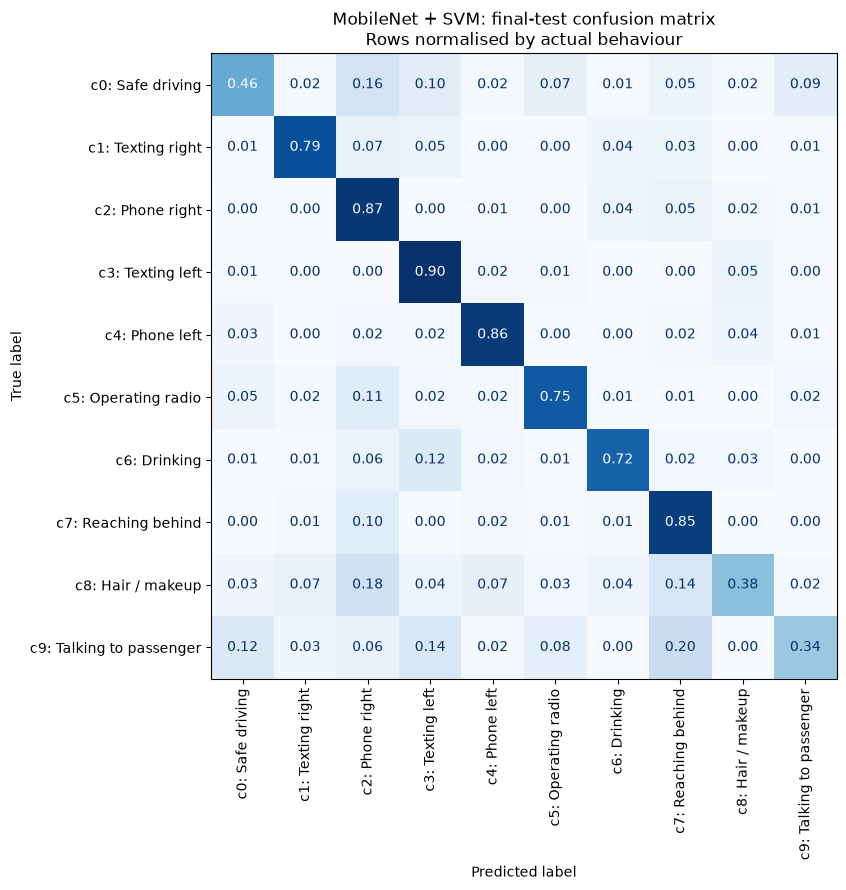

Distracted images classified as safe: 2.70%
Safe-driving images classified as distracted: 53.90%


In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

# Class order follows the State Farm labels c0–c9.
class_names = [
    "c0: Safe driving",
    "c1: Texting right",
    "c2: Phone right",
    "c3: Texting left",
    "c4: Phone left",
    "c5: Operating radio",
    "c6: Drinking",
    "c7: Reaching behind",
    "c8: Hair / makeup",
    "c9: Talking to passenger",
]
class_ids = np.arange(10)

# Summarise precision, recall and F1 for every behaviour.
report = classification_report(
    y_test,
    final_mobile_predictions,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
per_class_results = pd.DataFrame(report).T
display(
    per_class_results.loc[
        class_names, ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

# Normalise each row to show how each actual behaviour is classified.
cm_normalized = confusion_matrix(
    y_test,
    final_mobile_predictions,
    labels=class_ids,
    normalize="true",
)

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names,
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=90,
    colorbar=False,
)
ax.set_title("MobileNet + SVM: final-test confusion matrix\n"
             "Rows normalised by actual behaviour")
plt.tight_layout()
plt.show()

# Measure two safety-relevant errors separately from ten-class accuracy.
actual = np.asarray(y_test)
predicted = np.asarray(final_mobile_predictions)

distracted = actual != 0
safe = actual == 0

missed_distraction_rate = (
    (predicted[distracted] == 0).mean()
    if distracted.any() else np.nan
)
false_alarm_rate = (
    (predicted[safe] != 0).mean()
    if safe.any() else np.nan
)

print(
    "Distracted images classified as safe: "
    f"{missed_distraction_rate:.2%}"
)
print(
    "Safe-driving images classified as distracted: "
    f"{false_alarm_rate:.2%}"
)

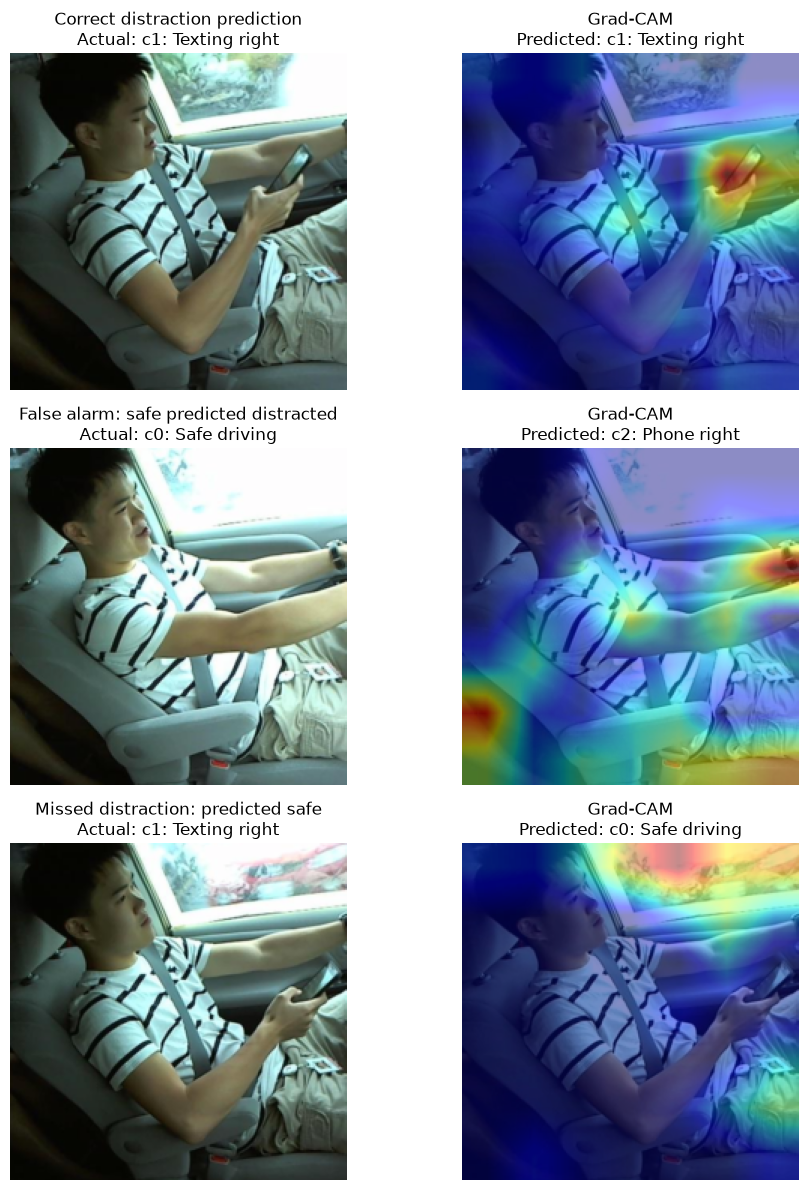

In [25]:
import torch.nn.functional as F

# Recreate the fitted scaler and SVM score calculation in PyTorch.
# This allows gradients through the actual final prediction pipeline.
scaler = final_mobile_classifier.named_steps["standardscaler"]
svm = final_mobile_classifier.named_steps["linearsvc"]

cam_mean = torch.tensor(scaler.mean_, dtype=torch.float32)
cam_scale = torch.tensor(scaler.scale_, dtype=torch.float32)
cam_weights = torch.tensor(svm.coef_, dtype=torch.float32)
cam_bias = torch.tensor(svm.intercept_, dtype=torch.float32)

# Use CPU for these three explanations to keep gradient handling simple.
mobile_model = mobile_model.to("cpu").eval()
cam_dataset = MobileNetTestDataset(test_df)

# Select the first example of each outcome, without choosing attractive maps.
actual = np.asarray(y_test)
predicted = np.asarray(final_mobile_predictions)

example_masks = {
    "Correct distraction prediction":
        (actual != 0) & (predicted == actual),
    "False alarm: safe predicted distracted":
        (actual == 0) & (predicted != 0),
    "Missed distraction: predicted safe":
        (actual != 0) & (predicted == 0),
}

cam_examples = [
    (description, int(np.flatnonzero(mask)[0]))
    for description, mask in example_masks.items()
    if mask.any()
]

fig, axes = plt.subplots(
    len(cam_examples), 2,
    figsize=(10, 4 * len(cam_examples)),
    squeeze=False,
)

for row, (description, idx) in enumerate(cam_examples):
    # Clone the preprocessed tensor to enable gradients.
    image_tensor = cam_dataset[idx].detach().clone()
    inputs = image_tensor.unsqueeze(0).requires_grad_(True)
    captured = {}

    def capture_activations(module, arguments, output):
        captured["activations"] = output

    hook = mobile_model.features[-1].register_forward_hook(
        capture_activations
    )

    try:
        with torch.enable_grad():
            features = mobile_model(inputs)
            scores = (
                (features - cam_mean) / cam_scale
            ) @ cam_weights.T + cam_bias

            # Confirm that the reconstructed scores match scikit-learn.
            reference = final_mobile_classifier.decision_function(
                features.detach().numpy()
            )
            np.testing.assert_allclose(
                scores.detach().numpy(),
                reference,
                rtol=1e-3,
                atol=1e-4,
            )

            predicted_class = int(predicted[idx])
            class_position = int(
                np.flatnonzero(svm.classes_ == predicted_class)[0]
            )

            activations = captured["activations"]
            gradients = torch.autograd.grad(
                scores[0, class_position], activations
            )[0]

            # Weight feature maps by their average spatial gradients.
            spatial_weights = gradients.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu(
                (spatial_weights * activations).sum(dim=1, keepdim=True)
            )
            cam = F.interpolate(
                cam,
                size=inputs.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )[0, 0]

            peak = cam.max().item()
            cam = (cam / peak if peak > 0 else cam).detach().numpy()

    finally:
        hook.remove()

    # Undo ImageNet normalization for displaying the model's input crop.
    image_mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    image_std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    display_image = (
        image_tensor * image_std + image_mean
    ).clamp(0, 1).permute(1, 2, 0).numpy()

    axes[row, 0].imshow(display_image)
    axes[row, 0].set_title(
        f"{description}\nActual: {class_names[int(actual[idx])]}"
    )

    axes[row, 1].imshow(display_image)
    axes[row, 1].imshow(
        cam, cmap="jet", alpha=0.45, vmin=0, vmax=1
    )
    axes[row, 1].set_title(
        f"Grad-CAM\nPredicted: {class_names[predicted_class]}"
    )

    if peak == 0:
        print(f"Image {idx}: no positive Grad-CAM activation.")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

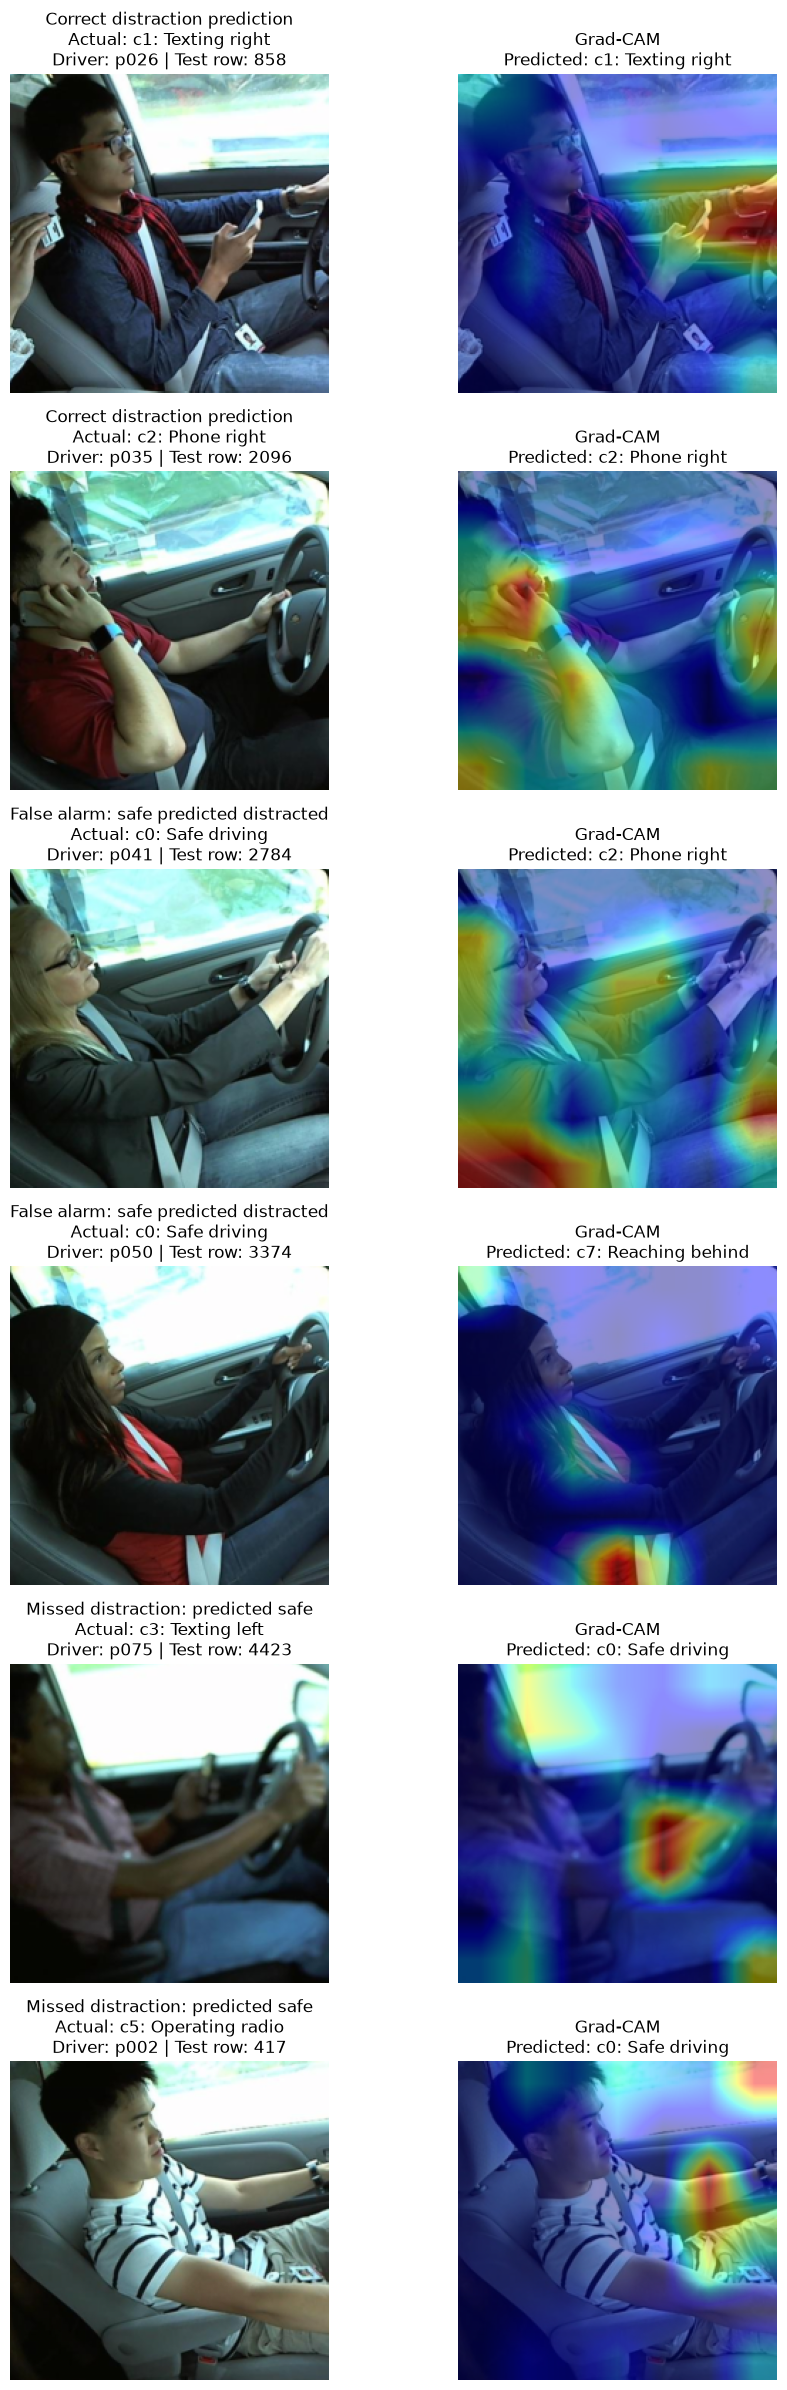

,Test row,Driver,Outcome,Actual,Predicted
0,858,p026,Correct distraction prediction,c1: Texting right,c1: Texting right
1,2096,p035,Correct distraction prediction,c2: Phone right,c2: Phone right
2,2784,p041,False alarm: safe predicted distracted,c0: Safe driving,c2: Phone right
3,3374,p050,False alarm: safe predicted distracted,c0: Safe driving,c7: Reaching behind
4,4423,p075,Missed distraction: predicted safe,c3: Texting left,c0: Safe driving
5,417,p002,Missed distraction: predicted safe,c5: Operating radio,c0: Safe driving


In [26]:
# Select additional examples deterministically, without inspecting heatmaps.
# Avoid the three images already explained.
excluded_indices = {idx for _, idx in cam_examples}

driver_column = next(
    (
        col for col in ["subject", "driver", "driver_id", "driver_subject"]
        if col in test_df.columns
    ),
    None,
)

actual = np.asarray(y_test)
predicted = np.asarray(final_mobile_predictions)

example_masks = {
    "Correct distraction prediction":
        (actual != 0) & (predicted == actual),
    "False alarm: safe predicted distracted":
        (actual == 0) & (predicted != 0),
    "Missed distraction: predicted safe":
        (actual != 0) & (predicted == 0),
}

# Include earlier drivers when prioritizing new ones.
seen_drivers = (
    {
        str(test_df.iloc[idx][driver_column])
        for idx in excluded_indices
    }
    if driver_column else set()
)

additional_examples = []

for description, mask in example_masks.items():
    candidates = [
        int(idx) for idx in np.flatnonzero(mask)
        if int(idx) not in excluded_indices
    ]
    seen_classes = set()

    for _ in range(2):
        if not candidates:
            break

        # Prefer a new driver, then a new actual class, then lowest row index.
        def selection_key(idx):
            driver_seen = (
                str(test_df.iloc[idx][driver_column]) in seen_drivers
                if driver_column else False
            )
            return (
                driver_seen,
                int(actual[idx]) in seen_classes,
                idx,
            )

        idx = min(candidates, key=selection_key)
        candidates.remove(idx)
        additional_examples.append((description, idx))
        seen_classes.add(int(actual[idx]))

        if driver_column:
            seen_drivers.add(str(test_df.iloc[idx][driver_column]))

# Use the same final model, scaler, SVM and preprocessing.
mobile_model = mobile_model.to("cpu").eval()
cam_dataset = MobileNetTestDataset(test_df)

fig, axes = plt.subplots(
    len(additional_examples), 2,
    figsize=(10, 4 * len(additional_examples)),
    squeeze=False,
)

example_details = []

for row, (description, idx) in enumerate(additional_examples):
    image_tensor = cam_dataset[idx].detach().clone()
    inputs = image_tensor.unsqueeze(0).requires_grad_(True)
    captured = {}

    def capture_activations(module, arguments, output):
        captured["activations"] = output

    hook = mobile_model.features[-1].register_forward_hook(
        capture_activations
    )

    try:
        with torch.enable_grad():
            features = mobile_model(inputs)
            scores = (
                (features - cam_mean) / cam_scale
            ) @ cam_weights.T + cam_bias

            # Verify the reconstructed pipeline against the fitted SVM.
            np.testing.assert_allclose(
                scores.detach().numpy(),
                final_mobile_classifier.decision_function(
                    features.detach().numpy()
                ),
                rtol=1e-3,
                atol=1e-4,
            )

            predicted_class = int(predicted[idx])
            class_position = int(
                np.flatnonzero(svm.classes_ == predicted_class)[0]
            )

            activations = captured["activations"]
            gradients = torch.autograd.grad(
                scores[0, class_position], activations
            )[0]

            spatial_weights = gradients.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu(
                (spatial_weights * activations).sum(dim=1, keepdim=True)
            )
            cam = F.interpolate(
                cam,
                size=inputs.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )[0, 0]

            peak = cam.max().item()
            cam = (cam / peak if peak > 0 else cam).detach().numpy()

    finally:
        hook.remove()

    # Display the exact cropped image seen by MobileNet.
    image_mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    image_std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    display_image = (
        image_tensor * image_std + image_mean
    ).clamp(0, 1).permute(1, 2, 0).numpy()

    driver = (
        str(test_df.iloc[idx][driver_column])
        if driver_column else "Unavailable"
    )

    axes[row, 0].imshow(display_image)
    axes[row, 0].set_title(
        f"{description}\n"
        f"Actual: {class_names[int(actual[idx])]}\n"
        f"Driver: {driver} | Test row: {idx}"
    )

    axes[row, 1].imshow(display_image)
    axes[row, 1].imshow(
        cam, cmap="jet", alpha=0.45, vmin=0, vmax=1
    )
    axes[row, 1].set_title(
        f"Grad-CAM\nPredicted: {class_names[predicted_class]}"
    )

    if peak == 0:
        print(f"Test row {idx}: no positive Grad-CAM activation.")

    for ax in axes[row]:
        ax.axis("off")

    example_details.append({
        "Test row": idx,
        "Driver": driver,
        "Outcome": description,
        "Actual": class_names[int(actual[idx])],
        "Predicted": class_names[predicted_class],
    })

plt.tight_layout()
plt.show()
display(pd.DataFrame(example_details))

,Driver,Images,Accuracy,Macro F1,Safe images,Distracted images,False alarm rate,Missed distraction rate
4,p050,790,0.4797,0.4131,123,667,0.6911,0.0075
5,p075,814,0.6388,0.6327,81,733,0.5556,0.0341
3,p041,605,0.7041,0.6759,60,545,0.2833,0.0642
1,p026,1196,0.7115,0.6415,130,1066,0.9615,0.0028
0,p002,725,0.7766,0.7365,76,649,0.2105,0.0632
2,p035,848,0.8856,0.8792,94,754,0.1702,0.0133


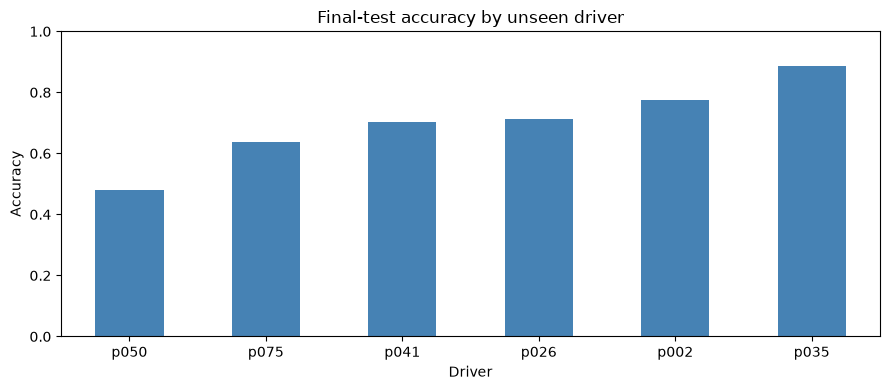

In [27]:
# Compare final-test performance across drivers.
# Differences describe performance disparities, not their causes.
driver_results = []

for driver, indices in test_df.groupby(driver_column).indices.items():
    indices = np.asarray(indices)
    labels = np.asarray(y_test)[indices]
    predictions = np.asarray(final_mobile_predictions)[indices]

    safe_mask = labels == 0
    distracted_mask = labels != 0

    driver_results.append({
        "Driver": driver,
        "Images": len(indices),
        "Accuracy": accuracy_score(labels, predictions),
        "Macro F1": f1_score(
            labels,
            predictions,
            labels=np.arange(10),
            average="macro",
            zero_division=0,
        ),
        "Safe images": int(safe_mask.sum()),
        "Distracted images": int(distracted_mask.sum()),
        "False alarm rate": (
            (predictions[safe_mask] != 0).mean()
            if safe_mask.any() else np.nan
        ),
        "Missed distraction rate": (
            (predictions[distracted_mask] == 0).mean()
            if distracted_mask.any() else np.nan
        ),
    })

driver_results_df = pd.DataFrame(driver_results).sort_values("Accuracy")
display(driver_results_df.round(4))

# Visualise variation between held-out drivers.
ax = driver_results_df.plot.bar(
    x="Driver",
    y="Accuracy",
    legend=False,
    figsize=(9, 4),
    ylim=(0, 1),
    color="steelblue",
)
ax.set_ylabel("Accuracy")
ax.set_title("Final-test accuracy by unseen driver")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
# Identify existing HOG features and classical-model variables.
for name, value in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(term in name.lower() for term in ["hog", "svm", "classical"]):
        shape = getattr(value, "shape", None)
        print(
            f"{name}: {type(value).__name__}"
            + (f" | shape={shape}" if shape is not None else "")
        )

hog: function
HOG_PARAMS: dict
hog_features: ndarray | shape=(1260,)
hog_image: ndarray | shape=(96, 128)
extract_hog_features: function
X_hog_dev: ndarray | shape=(17446, 1260)
svm_pipeline: Pipeline
svm_search: GridSearchCV
fast_svm: Pipeline
svm_fold_results: list
svm_oof_predictions: ndarray | shape=(17446,)
svm_cv_results: DataFrame | shape=(5, 7)
svm: LinearSVC


In [29]:
from sklearn.base import clone

# Preserve the classical pipeline's existing hyperparameters.
# Fit a fresh copy using all development images.
final_hog_classifier = clone(fast_svm)
comparison_start = perf_counter()

print("Fitting HOG + SVM on all development data...", flush=True)
final_hog_classifier.fit(X_hog_dev, np.asarray(y_dev))

# Use the existing HOG extraction function and original test-image paths.
if path_column is None:
    raise ValueError(
        "Original image-path column was not detected. "
        "Send test_df.columns and the extract_hog_features definition."
    )

# Check one image before processing the full test set.
first_hog = np.asarray(
    extract_hog_features(test_df.iloc[0][path_column])
).reshape(-1)

assert first_hog.size == X_hog_dev.shape[1], (
    f"Feature mismatch: test={first_hog.size}, "
    f"development={X_hog_dev.shape[1]}"
)

test_hog_rows = [first_hog]

for idx in range(1, len(test_df)):
    features = extract_hog_features(test_df.iloc[idx][path_column])
    test_hog_rows.append(np.asarray(features).reshape(-1))

    if (idx + 1) % 500 == 0:
        print(
            f"HOG final-test features: {idx + 1}/{len(test_df)}",
            flush=True,
        )

X_hog_test = np.vstack(test_hog_rows)

# Evaluate without changing hyperparameters based on test results.
final_hog_predictions = final_hog_classifier.predict(X_hog_test)
final_hog_metrics = calculate_metrics(y_test, final_hog_predictions)

final_comparison = pd.DataFrame(
    [final_hog_metrics, final_mobile_metrics],
    index=["HOG + SVM", "MobileNet features + SVM"],
)

display(final_comparison.round(4))
print(
    f"Comparison runtime: "
    f"{(perf_counter() - comparison_start) / 60:.1f} minutes"
)

Fitting HOG + SVM on all development data...
HOG final-test features: 500/4978
HOG final-test features: 1000/4978
HOG final-test features: 1500/4978
HOG final-test features: 2000/4978
HOG final-test features: 2500/4978
HOG final-test features: 3000/4978
HOG final-test features: 3500/4978
HOG final-test features: 4000/4978
HOG final-test features: 4500/4978


,Accuracy,Precision,Recall,Macro F1
HOG + SVM,0.5800,0.6595,0.5780,0.5897
MobileNet features + SVM,0.7011,0.7087,0.6913,0.6823


Comparison runtime: 0.3 minutes


In [30]:
# Train the original CNN architecture on all development data.
# Keep its original settings; do not tune using final-test results.
torch.manual_seed(SEED)
final_cnn = DriverCNN().to(device)

final_cnn_optimizer = torch.optim.Adam(
    final_cnn.parameters(),
    lr=0.001,
    weight_decay=0.0001,
)

final_cnn_train_loader = DataLoader(
    DriverImageDataset(dev_df),
    batch_size=64,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)

final_cnn_test_loader = DataLoader(
    DriverImageDataset(test_df),
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

for epoch in range(1, 6):
    epoch_start = perf_counter()
    final_cnn.train()
    loss_sum = 0.0

    for images, labels in final_cnn_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        final_cnn_optimizer.zero_grad(set_to_none=True)
        outputs = final_cnn(images)
        loss = criterion(outputs, labels)
        loss.backward()
        final_cnn_optimizer.step()

        loss_sum += loss.item() * labels.size(0)

    synchronize_device()
    print(
        f"Final CNN | Epoch {epoch}/5 | "
        f"Loss: {loss_sum / len(dev_df):.4f} | "
        f"Time: {perf_counter() - epoch_start:.1f}s",
        flush=True,
    )

# Evaluate after the fixed final epoch.
final_cnn.eval()
cnn_test_labels = []
cnn_test_predictions = []

with torch.inference_mode():
    for images, labels in final_cnn_test_loader:
        outputs = final_cnn(images.to(device))
        cnn_test_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )
        cnn_test_labels.extend(labels.numpy())

final_cnn_predictions = np.asarray(cnn_test_predictions)
np.testing.assert_array_equal(np.asarray(cnn_test_labels), y_test)

final_cnn_metrics = calculate_metrics(y_test, final_cnn_predictions)
final_cnn.to("cpu")

# All three approaches are now evaluated on identical final-test images.
final_comparison = pd.DataFrame(
    [final_hog_metrics, final_cnn_metrics, final_mobile_metrics],
    index=[
        "HOG + SVM — classical",
        "Small CNN — deep learning",
        "MobileNet + SVM — hybrid",
    ],
)
display(final_comparison.round(4))


Final CNN | Epoch 1/5 | Loss: 1.7082 | Time: 33.4s
Final CNN | Epoch 2/5 | Loss: 0.9381 | Time: 32.8s
Final CNN | Epoch 3/5 | Loss: 0.6219 | Time: 32.7s
Final CNN | Epoch 4/5 | Loss: 0.4495 | Time: 32.6s
Final CNN | Epoch 5/5 | Loss: 0.3604 | Time: 33.0s


,Accuracy,Precision,Recall,Macro F1
HOG + SVM — classical,0.5800,0.6595,0.5780,0.5897
Small CNN — deep learning,0.3775,0.5223,0.3768,0.3577
MobileNet + SVM — hybrid,0.7011,0.7087,0.6913,0.6823
